## COMP47750 Assignment 1
### Evaluating Categorical Encoding Methods

Student Name: Ellen Lyons

Student Number: 26117753


In [1]:
import pandas as pd
import numpy as np
import statistics
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.naive_bayes import MultinomialNB, GaussianNB, CategoricalNB
from sklearn.metrics import accuracy_score
from category_encoders import CatBoostEncoder

df = pd.read_csv("diabetes_70k.csv")
df.head()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,class
0,1,0,1,31,1,0,0,0,0,0,...,0,1,5,0,0,0,10,4,7,0
1,1,1,1,27,0,0,0,1,0,1,...,0,2,0,0,0,0,11,5,7,0
2,0,1,1,32,1,0,1,0,1,1,...,0,5,0,15,1,0,10,5,5,0
3,0,1,1,23,1,1,0,1,1,0,...,0,2,0,3,0,0,12,5,8,0
4,0,1,1,37,1,0,0,0,0,1,...,0,3,21,14,1,0,6,5,1,0


We weren't given information about the dataset, but it looks like this is health indicators used to classify if someone has or doesn't have diabetes. Most data is given in ``0/1`` format, so High/Low, Yes/No answers. The Age category is presumably already binned, because the people who gave data were likely not children aged 1 - 13. *GenHlth*, *PhysHlth* and *MentHlth* are some sort of scale corresponding to how the patient feels.

In [2]:
# check for missing values in dataset
#df.isnull().sum()

# check the dtypes of the data
#df.dtypes

In [3]:
y = df.pop("class").values # Set this as the y (target)
X = df.values

### Task 1: OneHotEncoder vs OrdinalEncoder with Naive Bayes
I am going to start by tackling the OneHotEncoder --> Multinomial NB pipeline, get this to work and then move on to making a loop with OrdinalEncoding too. 

From the documentation (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) I see that ``train_test_split()`` has an argument ``random_state`` which controls the shuffling applied to the data before applying the split. I will make a loop that runs 20 times and randomises this split each time.

In [4]:
# define the encoders 
onehot_encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore") # handle_unknown is needed later

unknown_code = df["BMI"].nunique()  # BMI's category count is the largest in the set 
# the arguments used below are needed for Task 3
ordinal_encoder = OrdinalEncoder(handle_unknown="use_encoded_value",
                                 unknown_value=unknown_code)
# encode the data
X_OH = onehot_encoder.fit_transform(X)
X_OD = ordinal_encoder.fit_transform(X)

# classifiers
mnb = MultinomialNB()
# need to make sure categorical encoder knows how many different values each column can have
# I think this is a common issue: https://github.com/scikit-learn/scikit-learn/issues/16028
# give CategoricalNB enough slots for every real code plus the unknown code used
cnb = CategoricalNB(min_categories=unknown_code + 1) 

# accuracy scores 
OH_scores_before_split, OD_scores_before_split = [], []

# loop 20 times 
for seed in range(1,21,1):
    
    # split data 50:50 
    X_train_OH, X_test_OH, y_train_OH, y_test_OH = train_test_split(X_OH, y, test_size = 0.5, random_state = seed)
    X_train_OD, X_test_OD, y_train_OD, y_test_OD = train_test_split(X_OD, y, test_size = 0.5, random_state = seed)
    
    # apply multinomial classifier
    df_mnb = mnb.fit(X_train_OH, y_train_OH)
    y_pred_OH = df_mnb.predict(X_test_OH)

    # apply categorical classifier
    df_cnb = cnb.fit(X_train_OD, y_train_OD)
    y_pred_OD = df_cnb.predict(X_test_OD)

    # determine the accuracy score
    accuracy_OH = accuracy_score(y_test_OH, y_pred_OH) 
    accuracy_OD = accuracy_score(y_test_OD, y_pred_OD)
    OH_scores_before_split.append(accuracy_OH)
    OD_scores_before_split.append(accuracy_OD)
    #print(f"OH run {seed}: accuracy =  {accuracy_OH:.4f}")

print(f"Average accuracy for the OneHotEncoder: {statistics.mean(OH_scores_before_split)}")
print(f"Average accuracy for the OrdinalEncoder: {statistics.mean(OD_scores_before_split)}")

Average accuracy for the OneHotEncoder: 0.7332286538787982
Average accuracy for the OrdinalEncoder: 0.7332300684660216


The average accuracy for both the ``OneHotEncoder`` and the ``OrdinalEncoder`` is $\approx 0.733$. There is small deviation between the two accuracies, but they are essentially the same value. 

### Task 2:  CatBoostEncoder with GaussianNB

In [5]:
# CatBoostEncoder only encodes category/text columns, so convert to category
X_str = df.astype("category")

CB_encoder = CatBoostEncoder() # define encoder
X_CB = CB_encoder.fit_transform(X_str, y) # use shuffled values in encoder

gnb = GaussianNB()

CB_scores_before_split = []

for seed in range(1,21,1):
    X_train_CB, X_test_CB, y_train_CB, y_test_CB = train_test_split(X_CB, y, test_size = 0.5, random_state = seed)

    df_gnb = gnb.fit(X_train_CB, y_train_CB)
    y_pred_CB = df_gnb.predict(X_test_CB)
    accuracy_CB = accuracy_score(y_test_CB, y_pred_CB)
    CB_scores_before_split.append(accuracy_CB)
    #print(f"CB run {seed}: accuracy =  {accuracy_CB:.4f}")

print(f"Average accuracy for the CatBoostEncoder: {statistics.mean(CB_scores_before_split):.3f}")

Average accuracy for the CatBoostEncoder: 0.990


### Task 3: Fit Encoders After Splitting the Data

In [6]:
# accuracy scores 
OH_scores, OD_scores, CB_scores = [], [], []

# loop 20 times 
for seed in range(1,21,1):
    
    # split data 50:50 FIRST
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.5, random_state = seed)
    X_train_str, X_test_str = train_test_split(X_str, test_size=0.5, random_state=seed) # need categorical data for the CB

    # fit encoders on training data only 
    X_train_OH = onehot_encoder.fit_transform(X_train)
    X_train_OD = ordinal_encoder.fit_transform(X_train)
    X_train_CB = CB_encoder.fit_transform(X_train_str, y_train)

    # same for test data 
    # i was confused about this but then i read https://www.tutorialspoint.com/article/categorical-encoding-with-catboost-encoder-in-machine-learning
    X_test_OH = onehot_encoder.transform(X_test)
    X_test_OD = ordinal_encoder.transform(X_test)
    X_test_CB = CB_encoder.transform(X_test_str) # .transform for the test data 
    
    # apply multinomial classifier
    df_mnb = mnb.fit(X_train_OH, y_train)
    y_pred_OH = df_mnb.predict(X_test_OH)

    # apply categorical classifier
    df_cnb = cnb.fit(X_train_OD, y_train)
    y_pred_OD = df_cnb.predict(X_test_OD)

    # apply gaussian classifier
    df_gnb = gnb.fit(X_train_CB, y_train)
    y_pred_CB = df_gnb.predict(X_test_CB)

    # determine the accuracy score
    accuracy_OH = accuracy_score(y_test, y_pred_OH) 
    accuracy_OD = accuracy_score(y_test, y_pred_OD)
    accuracy_CB = accuracy_score(y_test, y_pred_CB)

    OH_scores.append(accuracy_OH)
    OD_scores.append(accuracy_OD)
    CB_scores.append(accuracy_CB)

print(f"Average accuracy for the OneHotEncoder: {statistics.mean(OH_scores):}")
print(f"Average accuracy for the OrdinalEncoder: {statistics.mean(OD_scores):}")
print(f"Average accuracy for the CatBoostEncoder: {statistics.mean(CB_scores):}")

"""if statistics.mean(OH_scores) > statistics.mean(OD_scores) and statistics.mean(OH_scores) > statistics.mean(CB_scores):
    print("The OneHotEncoder performed best!")

elif statistics.mean(OD_scores) > statistics.mean(OH_scores) and statistics.mean(OD_scores) > statistics.mean(CB_scores):
    print("The OrdinalEncoder performed best!")

else:
    print("The CatBoostEncoder performed best!")"""
# it is basically a tie between onehot and ordinal

Average accuracy for the OneHotEncoder: 0.7332286538787982
Average accuracy for the OrdinalEncoder: 0.7332300684660216
Average accuracy for the CatBoostEncoder: 0.7280951168449047


'if statistics.mean(OH_scores) > statistics.mean(OD_scores) and statistics.mean(OH_scores) > statistics.mean(CB_scores):\n    print("The OneHotEncoder performed best!")\n\nelif statistics.mean(OD_scores) > statistics.mean(OH_scores) and statistics.mean(OD_scores) > statistics.mean(CB_scores):\n    print("The OrdinalEncoder performed best!")\n\nelse:\n    print("The CatBoostEncoder performed best!")'

The accuracy scores for the OneHotEncoder and the OrdinalEncoder are the same now as they were when I encoded the data *before* splitting it. However, the accuracy for the CatBoostEncoder has reduced.

IBM describe data leakage well (https://www.ibm.com/think/topics/data-leakage-machine-learning):

"Data leakage happens when data from outside the training dataset is used to create the model, but this future data will not be available when the model is used for prediction. The model will perform well in testing and validation, but when used in production, it becomes entirely inaccurate."

There are two types of leakage: 

- Target leakage is when models include data that they won't see when classifying a query. This leads to the model performing really well on test data, giving a falsely high accuracy, but it would not perform this well on a real query.
- Train-test contamination is when both training and validation data are used to create a model because of improper preprocessing/splitting.

Using the OneHot and Ordinal encoders before splitting the data is a form of test-train contamination, but in this case, there was no real measurable difference, as the accuracy in task 1 is the same as task 3. This is because the encoders only learn on ``X``and not ``y``. 

Using the CatBoost encoder before splitting the dataset also leads to test-train contamination, but more so target leakage, as the CatBoost takes into account both ``X`` and ``y``. The Cat Boost encoder is assigning a mean variable to each category based on the target's value, so this means if the encoder is fitted on the whole dataset, the labels of the test rows are used to calculate the encodings. This is probably why the accuracy was 0.99 in task 2! It is not proper practise in ML to encode before splitting data.

### Task 4: Visual Comparison of Results

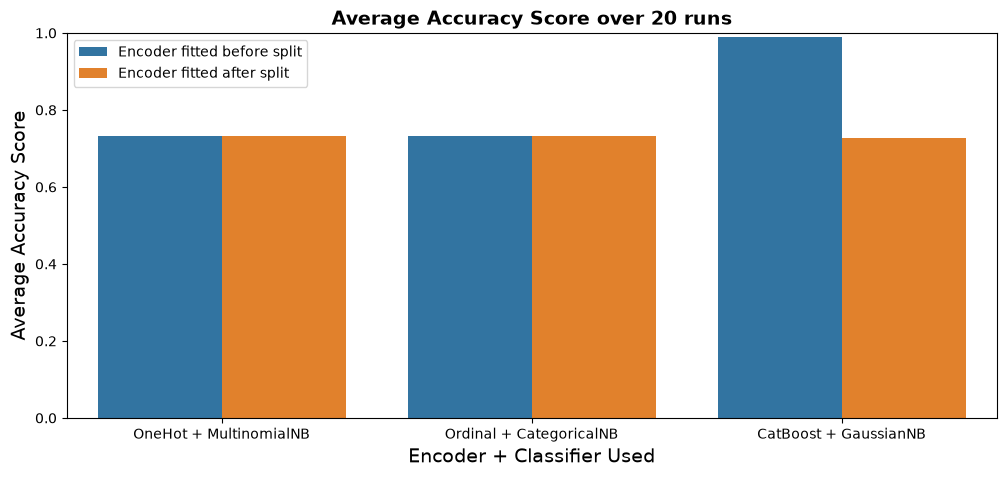

In [7]:
# plot with seaborn
names = ["OneHot + MultinomialNB", "Ordinal + CategoricalNB", "CatBoost + GaussianNB"]
avg_after_split = [statistics.mean(OH_scores), statistics.mean(OD_scores), statistics.mean(CB_scores)]
avg_before_split = [statistics.mean(OH_scores_before_split), statistics.mean(OD_scores_before_split), statistics.mean(CB_scores_before_split)]

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=names * 2,
            y=avg_before_split + avg_after_split,
            hue=["Encoder fitted before split"] * 3 + ["Encoder fitted after split"] * 3,
            ax=ax)

ax.set_ylim(0, 1)
ax.set_ylabel("Average Accuracy Score", fontsize=14)
ax.set_xlabel("Encoder + Classifier Used", fontsize=14)
ax.set_title("Average Accuracy Score over 20 runs", fontsize=14, fontweight="bold")
plt.show()

### Task 5: Markdown Commentary
*Which encoder performed best overall?*

As we can see in the barcharts, the CatBoost encoder performed the best when used before splitting the data, but this was due to data leakage. So, in reality, each encoder performed equally well, with the accuracy score of each approx 0.73.

*How did the choice of Naive Bayes variant affect results?*

A different NB classifier was used for each encoder, so this means we don't have a "fair" comparison for what encoder is the "best". However, the choice of NB classifier was suited best to each encoder, for example, it wouldn't make sense to use multinomialNB with Ordinal because the multinomial classifier would overcount.

*What is the effect of fitting encoders before vs. after splitting?*

For the OneHot and Ordinal encoder, there was negligible effect on the accuracy whether I split before or after encoding, because they never the see class column. But for the CatBoost encoder, the accuracy was lower when I encoded only the training data. This was due to data leakage as discussed. 

OneHot + MultinomialNB and Ordinal + CategoricalNB give the same results because they are essentially doing the same thing. 

*Any practical recommendations for handling categorical data in ML pipelines?*

'Feature engineering' is good practise in ML. Binning data, such as the BMI column in this assignment, is a good idea as it simplifies the dataset. As mentioned in lectures, binning can reduce the 'Curse of Dimensionality'; so in this case, if I had binned the BMI values, then this would have reduced the amount of columns that were created. Also, BMI is really numerical data, so treating it as categorical here doesn't make sense. 

The best pipeline is to treat each feature individually, some will be categorical, some nuemrical, some ordinal. Then select the encoder specific to each one. Split data *before* encoding.


### ADDITIONAL DISCUSSION

I was confused about the accuracy of the CatBoost when used before splitting data. I expect the accuracy to be high due to data leakage, but 0.99 is saying that the accuracy is essentially perfect? But then, I realised that the ``OneHotEncoder`` and the ``OrdinalEncoder`` only take ``X`` as an argument, whereas here both ``X`` and ``y`` are arguments. I looked at the raw data, and the 'class' column has all of the 0 values in order followed by all of the 1 values. However, I thought that I was randomising things so this wouldn't matter. 

But THEN I realised, no, I am not randomising the ``y`` values and the model is seeing the order of all 0s and all 1s, making it very easy to classify the test data, hence giving misleadingly high accuracy. Below I used ``shuffle`` to mix up the ``X``and ``y``, then I used the encoder, then I split the data and classified.

In [8]:
# i need to shuffle the 'class' data
from sklearn.utils import shuffle
# https://scikit-learn.org/stable/modules/generated/sklearn.utils.shuffle.html

# CatBoostEncoder only encodes category/text columns, so convert to category
X_str = df.astype("category")

# shuffle
X_str_shuf, y_shuf = shuffle(X_str, y, random_state=0)  

CB_encoder = CatBoostEncoder() # define encoder
X_CB = CB_encoder.fit_transform(X_str_shuf, y_shuf) # use shuffled values in encoder

gnb = GaussianNB()

CB_scores_with_shuffling = []

for seed in range(1,21,1):
    X_train_CB, X_test_CB, y_train_CB, y_test_CB = train_test_split(X_CB, y_shuf, test_size = 0.5, random_state = seed)

    df_gnb = gnb.fit(X_train_CB, y_train_CB)
    y_pred_CB = df_gnb.predict(X_test_CB)
    accuracy_CB = accuracy_score(y_test_CB, y_pred_CB)
    CB_scores_with_shuffling.append(accuracy_CB)
    #print(f"CB run {seed}: accuracy =  {accuracy_CB:.4f}")

print(f"Average accuracy for the CatBoostEncoder when data is shuffled before encoding, but split after encoding: {statistics.mean(CB_scores_with_shuffling):.3f}")
print(f"Average accuracy for the CatBoostEncoder when data is split before encoding: {statistics.mean(CB_scores):.3f}")

Average accuracy for the CatBoostEncoder when data is shuffled before encoding, but split after encoding: 0.727
Average accuracy for the CatBoostEncoder when data is split before encoding: 0.728


Now we can see that the accuracy score before is a bit more realistic, but now there is negligible difference between the accuracy when encoding before data split vs encoding after data split. This is implying that data leakage is not a major issue for this dataset.

To be honest, I am a little confused about this, and I am not sure if this was really even part of the assignment at all, hence I have put it in as an aside. My conclusion is that the order of the rows *is* a form of data leakage. 